### Set autoreloading
This extension will automatically update with any changes to packages in real time

In [13]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [14]:
import os, sys
ROOT = f"/net/projects2/fermi2526/clinic-2026-fermi-neutrino-{os.environ['USER']}"
sys.path[:0] = [f"{ROOT}/external/nugraph/nugraph",f"{ROOT}/external/nugraph/pynuml",f"{ROOT}/src"]
os.environ.setdefault("NUGRAPH_DIR", f"{ROOT}/external/nugraph")
os.environ.setdefault("NUGRAPH_DATA", "/net/projects2/fermi2526/data")
os.environ.setdefault("NUGRAPH_LOG", f"/net/projects2/fermi2526/logs/{os.environ['USER']}")

'/net/projects2/fermi2526/logs/miacorduneanu'

In [15]:
import socket; print(socket.gethostname())

g007


### Import packages
We'll need the `nugraph` and `pynuml` packages imported in order to plot, and `torch` for some tensor operations later on

In [16]:
import os
from pathlib import Path
import nugraph as ng
import pynuml
import torch
import matplotlib.pyplot as plt
import plotly.graph_objects as go
print(ng.__file__)

/net/projects2/fermi2526/clinic-2026-fermi-neutrino-miacorduneanu/external/nugraph/nugraph/nugraph/__init__.py


### Set model and data to use

This allows the user to switch out different model architectures and datasets

In [17]:
DATA_PATH = "/net/projects2/fermi2526/data/nugraph3-dsi.optical.fix.renamed.gnn.h5"
os.environ["NUGRAPH_CKPT"] = "/net/projects2/fermi2526/logs/miacorduneanu/main/default/checkpoints/epoch=2-step=300.ckpt"
Data = ng.data.NuGraphDataModule
Model = ng.models.NuGraph3

### Configure data module
Declare a data module. If you're working on a standard cluster, the data file location should be configured automatically. If not, you'll need to configure it manually.

In [18]:
nudata = Data(model=Model, data_path=DATA_PATH, num_workers=0)

### Configure network
In order to test a trained model, we instantiate it using a checkpoint file. These are produced during training, so if you've trained a model, there should be an associated checkpoint in your output directory that you can pass here.

In [19]:
ckpt = os.environ.get("NUGRAPH_CKPT", "$PUT_CKPT_PATH_HERE$").strip()
model = None
if ckpt and Path(ckpt).exists():
    try:
        # strict=False only tolerates missing/unexpected keys, not shape mismatches
        model = Model.load_from_checkpoint(ckpt, map_location="cpu", strict=False)
        model.freeze()
    except RuntimeError as err:
        # checkpoint was trained with a different model architecture than the code in this repo
        print(f"Could not load {ckpt} with the current NuGraph3 code (architecture mismatch):\n"
              f"{str(err).splitlines()[0]}\n"
              "Point NUGRAPH_CKPT at a checkpoint trained with this code. Continuing without a model (no predictions).")
else:
    print("No checkpoint provided. Set NUGRAPH_CKPT to enable predictions.")

if model is not None:
    # ensure dataset feature extension matches checkpoint expectations (avoids dimension mismatches)
    expected = int(getattr(model, "in_features", 0) or model.hparams.get("in_features", 0) or 0)
    sample = nudata.train_dataset[0]["hit"].x.size(1)
    if expected and sample != expected:
        if sample + 4 == expected: # change number based on expected
            print(f"Rebuilding data module with featext=True ({sample} -> {expected} features)")
            nudata = Data(model=Model, data_path=DATA_PATH,
                         num_workers=0, featext=True)
        else:
            print(f"Warning: checkpoint expects {expected} input features, but data has {sample}.")


## Configure plotting utility
Instantiate the **pynuml** utility for plotting graph objects, which will do the heavy lifting for us here!

In [20]:
plot = pynuml.plot.GraphPlot(planes=nudata.planes,
                             classes=nudata.semantic_classes)

## Plot ground truth labels

### Iterable dataset

First we define an iterator over the test dataset:

In [21]:
test_iter = iter(nudata.test_dataset)

### Retrieve the next graph

This block retrieves a graph from the testing dataset, and passes it through the trained model. Since we defined `test_iter` as an iterator over the dataset, the following block can be executed multiple times, and each time it's executed, it will step to the next graph in the dataset.

In [22]:
data = next(test_iter)
md = data['metadata']
name = f'r{md.run}_sr{md.subrun}_e{md.event}'

# cache sumPE before model.step mutates node features into embeddings
if data['pmt'].x.size(1) > 3:
    pmt_sumpe = data['pmt'].x[:, 3].detach().cpu()
else:
    pmt_sumpe = torch.zeros(data['pmt'].num_nodes)

if model is not None:
    #model.step(data)
    model.predict_step(data)

### Plot a single graph

We can now use pynuml's plotting utilities to plot the graph as a figure. Each time you call the above block to retrieve a new graph, you can then re-execute the plotting blocks to re-plot with the new graph. Note these plots require a checkpoint path in the "Configure network" cell.

In [30]:
# true semantic labels

import plotly.io as pio  # claude modif!
pio.renderers.default = "plotly_mimetype+notebook_connected"  # claude modif! render without the anywidget-based FigureWidget

plot.plot(data, target='semantic', how='pred', filter='none')
plot.plot(data, target='semantic', how='true', filter='none')

plot.plot(data, target='semantic', how='pred', filter='show')
plot.plot(data, target='semantic', how='true', filter='show')

fig = plot.plot(data, target='semantic', how='true')
go.Figure(fig).show()  # claude modif!

In [31]:
# predicted semantic labels

import plotly.io as pio  # claude modif!
pio.renderers.default = "plotly_mimetype+notebook_connected"  # claude modif! render without the anywidget-based FigureWidget

plot.plot(data, target='semantic', how='pred', filter='none')
plot.plot(data, target='semantic', how='true', filter='none')

plot.plot(data, target='semantic', how='pred', filter='show')
plot.plot(data, target='semantic', how='true', filter='show')

fig = plot.plot(data, target='semantic', how='pred', filter='none') # filter ='none' to see semantic classifications of all points
#fig
go.Figure(fig).show() 

In [25]:
print(data['hit'].keys())
print(data['hit'].num_nodes)

KeysView({'plane': tensor([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1

### Plot optical PMT/spacepoint connectivity

This cell visualizes PMT and spacepoint positions in the y-z plane, colors PMTs by sumPE, and overlays the graph edges as constructed in `transform.py`:
- **pmt-pmt**: each PMT connected to its 3 nearest PMTs
- **pmt-sp**: each PMT connected to its 16 nearest spacepoints

Use the `SHOW_*` flags at the top of the next cell to toggle spacepoints, PMTs, pmt-pmt edges and pmt-sp edges.

Edges stored in the dataset are used when present; otherwise they are rebuilt with the same logic as the transform.

In [26]:
# --- plot display toggles: set to False to hide a layer ---
SHOW_SPACEPOINTS = True
SHOW_PMTS = True
SHOW_PMT_PMT_EDGES = True
SHOW_PMT_SP_EDGES = True

# edge construction mirroring transform.py
PMT_PMT_KNN = 3
PMT_SP_KNN = 16

def pmt_pmt_edges(graph):
    """pmt-pmt kNN edges. Uses the dataset's edges if present, else builds them as transform.py does."""
    if ('pmt', 'knn', 'pmt') in graph.edge_types:
        return graph['pmt', 'knn', 'pmt'].edge_index.detach().cpu().long()
    pos = graph['pmt'].pos.detach().cpu().float()
    n_pmt = pos.size(0)
    if n_pmt <= 1:
        return torch.empty((2, 0), dtype=torch.long)
    distances = torch.cdist(pos, pos, p=2)
    distances.fill_diagonal_(float('inf'))
    knn = min(PMT_PMT_KNN, n_pmt - 1)
    _, nbr = torch.topk(distances, knn, largest=False, dim=1)
    source = torch.arange(n_pmt, dtype=torch.long).repeat_interleave(knn)
    edges = torch.stack((source, nbr.flatten()), dim=0)
    return torch.cat((edges, edges.flip(0)), dim=1)  # both directions

def pmt_sp_edges(graph):
    """pmt->sp kNN edges (each PMT -> its 16 nearest spacepoints). Uses the dataset's edges if present,
    else builds them as the pmt-sp block in transform.py does. PMT pos is (y, z) and sp pos is (x, y, z),
    so distances are taken over the trailing shared dims (y, z)."""
    if ('pmt', 'knn', 'sp') in graph.edge_types:
        return graph['pmt', 'knn', 'sp'].edge_index.detach().cpu().long()
    ppos = graph['pmt'].pos.detach().cpu().float()
    spos = graph['sp'].pos.detach().cpu().float()
    n_pmt, n_sp = ppos.size(0), spos.size(0)
    if n_pmt == 0 or n_sp == 0:
        return torch.empty((2, 0), dtype=torch.long)
    d = min(ppos.size(-1), spos.size(-1))
    distances = torch.cdist(ppos[:, -d:], spos[:, -d:], p=2)
    knn = min(PMT_SP_KNN, n_sp)
    _, nbr = torch.topk(distances, knn, largest=False, dim=1)
    source = torch.arange(n_pmt, dtype=torch.long).repeat_interleave(knn)
    return torch.stack((source, nbr.flatten()), dim=0)

PMT-PMT edges: 156 (knn=3)
PMT-SP edges: 416 (knn=16 per PMT)


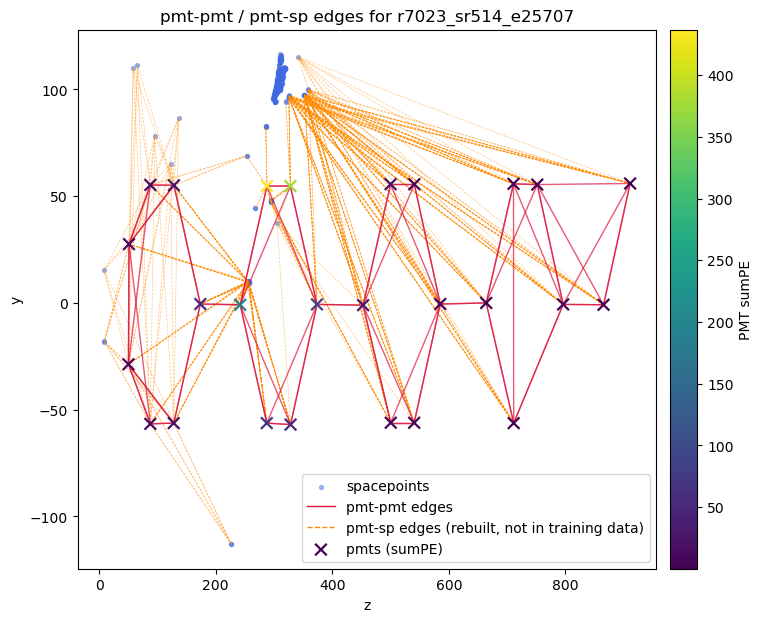

In [27]:
pmt_pos = data['pmt'].pos.cpu()
sp_pos = data['sp'].pos.cpu()

if 'pmt_sumpe' in locals() and pmt_sumpe.numel() == pmt_pos.size(0):
    pmt_sumpe_plot = pmt_sumpe
elif data['pmt'].x.size(1) > 3:
    pmt_sumpe_plot = data['pmt'].x[:, 3].detach().cpu()
else:
    pmt_sumpe_plot = torch.zeros(pmt_pos.size(0))

sp_y = sp_pos[:, 1] if sp_pos.size(1) > 1 else sp_pos[:, 0]
sp_z = sp_pos[:, 2] if sp_pos.size(1) > 2 else sp_pos[:, -1]
pmt_y = pmt_pos[:, 0]
pmt_z = pmt_pos[:, 1] if pmt_pos.size(1) > 1 else pmt_pos[:, 0]

pp_edges = pmt_pmt_edges(data)
ps_edges = pmt_sp_edges(data)
candidate_edges = int(ps_edges.size(1))

# edges rebuilt here (not stored in the dataset) were never seen in the training run: drawn dashed orange
ps_from_dataset = ('pmt', 'knn', 'sp') in data.edge_types
ps_style = dict(color='gray', linewidth=0.35, alpha=0.25, linestyle='-') if ps_from_dataset \
    else dict(color='darkorange', linewidth=0.5, alpha=0.5, linestyle='--')
ps_label = 'pmt-sp edges (dataset)' if ps_from_dataset else 'pmt-sp edges (rebuilt, not in training data)'

print(f'PMT-PMT edges: {pp_edges.size(1)} (knn={PMT_PMT_KNN})')
if not ps_from_dataset:
    print('WARNING: no (pmt, knn, sp) edges in this dataset; drawing rebuilt edges (dashed orange)')
print(f'PMT-SP edges: {candidate_edges} (knn={PMT_SP_KNN} per PMT)')

fig, ax = plt.subplots(figsize=(9, 7))
if SHOW_SPACEPOINTS:
    ax.scatter(sp_z, sp_y, s=8, alpha=0.45, color='royalblue', label='spacepoints')

for src, tgt in (ps_edges.t().tolist() if SHOW_PMT_SP_EDGES else []):
    ax.plot([pmt_z[src], sp_z[tgt]], [pmt_y[src], sp_y[tgt]], **ps_style)

# pmt-pmt edges are stored in both directions; draw each pair once
seen = set()
for a, b in (pp_edges.t().tolist() if SHOW_PMT_PMT_EDGES else []):
    if (b, a) in seen:
        continue
    seen.add((a, b))
    ax.plot([pmt_z[a], pmt_z[b]], [pmt_y[a], pmt_y[b]], color='crimson', linewidth=1.0, alpha=0.7)
if SHOW_PMT_PMT_EDGES:
    ax.plot([], [], color='crimson', linewidth=1.0, label='pmt-pmt edges')
if SHOW_PMT_SP_EDGES:
    ax.plot([], [], label=ps_label, **{**ps_style, 'linewidth': 1.0, 'alpha': 1.0})

if SHOW_PMTS:
    pmt_scatter = ax.scatter(pmt_z, pmt_y, s=70, c=pmt_sumpe_plot, cmap='viridis',
                             marker='x', linewidths=1.6, label='pmts (sumPE)', zorder=3)
    fig.colorbar(pmt_scatter, ax=ax, pad=0.02).set_label('PMT sumPE')

ax.set_xlabel('z')
ax.set_ylabel('y')
ax.set_title(f'pmt-pmt / pmt-sp edges for {name}')
if ax.get_legend_handles_labels()[0]:
    ax.legend(loc='best')
plt.show()

### Save plots to disk

We can also use plotly's `write_html` and `write_image` methods to print the figure as an interactive webpage, or in a raster graphics (ie. PNG, JPEG etc) or vector graphics (ie. PDF) format. By default this writes to a `plots` subdirectory – if you're seeing an error that this directory does not exist, simply create one, or change the path to a valid output location!

In [28]:
print(os.getcwd())
os.makedirs("plots/evd", exist_ok=True)

/net/spaces/clinic/fermi2526/clinic-2026-fermi-neutrino-miacorduneanu


In [ ]:
fig.write_html(f'plots/evd/{name}_semantic_true.html')
fig.write_image(f'plots/evd/{name}_semantic_true.png')
fig.write_image(f'plots/evd/{name}_semantic_true.pdf')

### (Optional) Select example events

The following blocks will select the representative events from the NuGraph2 paper

### Event 1

Run 5189, subrun 225, event 11300

In [33]:
data = nudata.test_dataset[64]
md = data['metadata']
name = f'r{md.run}_sr{md.subrun}_e{md.event}'
#model.step(data);
model.predict_step(data);

### Event 2

Run 6999, subrun 11, event 595

In [34]:
data = nudata.test_dataset[36]
md = data['metadata']
name = f'r{md.run}_sr{md.subrun}_e{md.event}'
#model.step(data);
model.predict_step(data);

### Event 3

Run 7048, subrun 177, event 8858

In [35]:
data = nudata.test_dataset[11]
md = data['metadata']
name = f'r{md.run}_sr{md.subrun}_e{md.event}'
#model.step(data);
model.predict_step(data);

### Event 4

Run 5459, subrun 94, event 4738

In [36]:
data = nudata.test_dataset[91]
md = data['metadata']
name = f'r{md.run}_sr{md.subrun}_e{md.event}'
#model.step(data);
model.predict_step(data);

### Event 5

Run 6780, subrun 200, event 10006

In [37]:
data = nudata.test_dataset[27]
md = data['metadata']
name = f'r{md.run}_sr{md.subrun}_e{md.event}'
#model.step(data);
model.predict_step(data);

### Plot event displays

Write event displays to disk in PDF format for use in the NuGraph2 paper.

In [38]:
plot.plot(data, target='filter', how='true', filter='none').write_image(f'plots/evd/{name}_filter_true.pdf')
plot.plot(data, target='filter', how='pred', filter='none').write_image(f'plots/evd/{name}_filter_pred.pdf')
plot.plot(data, target='semantic', how='true', filter='true').write_image(f'plots/evd/{name}_semantic_true.pdf')
plot.plot(data, target='semantic', how='pred', filter='pred').write_image(f'plots/evd/{name}_semantic_pred.pdf')

### Print model performance

Print out information on the rate at which the model makes mistakes, and some information on common failure modes.

In [39]:
#tf = torch.cat([(data[p].y_semantic!=-1) for p in nudata.planes])
#pf = torch.cat([data[p].x_filter.round() for p in nudata.planes])
#ts = torch.cat([data[p].y_semantic for p in nudata.planes])[tf]
#ps = torch.cat([data[p].x_semantic.argmax(dim=1) for p in nudata.planes])[tf]

tf = data['hit'].y_semantic != -1
pf = data['hit'].x_filter.round()
ts = data['hit'].y_semantic[tf]
ps = data['hit'].x_semantic.argmax(dim=1)[tf]
print(tf.sum().item(), "labeled hits of", tf.numel())

print(f'there are {tf.size(0)} hits overall, of which {tf.sum()} are signal.')

print('\n### Filter\n')

mask = tf != pf
print(f'{mask.sum()} hits were classified wrong. of those, {(tf[mask]==0).sum()} are false positives, and {(tf[mask]==1).sum()} are false negatives.')

print('\n### Semantic\n')

print(f'of the {tf.sum()} signal hits, {(ps==ts).sum()} are correctly classified.')

mask = ts != ps
print(f'of the {mask.sum()} misclassified hits:')

for i, c in enumerate(nudata.semantic_classes):
    tm = ts[mask]==i
    if tm.sum() == 0: continue
    print(f'- {tm.sum()} {c} hits were misclassified.')
    for j, cj in enumerate(nudata.semantic_classes):
        pm = ps[mask][tm]==j
        if pm.sum() == 0: continue
        print(f'  - {pm.sum()} as {cj}')

1845 labeled hits of 2279
there are 2279 hits overall, of which 1845 are signal.

### Filter

225 hits were classified wrong. of those, 101 are false positives, and 124 are false negatives.

### Semantic

of the 1845 signal hits, 1513 are correctly classified.
of the 332 misclassified hits:
- 157 muon hits were misclassified.
  - 157 as shower
- 175 diffuse hits were misclassified.
  - 104 as muon
  - 71 as shower


In [40]:
print(data.node_types)
print(data.edge_types)

['metadata', 'sp', 'hit', 'evt', 'particle-truth', 'ophit', 'flash', 'pmt', 'particle']
[('hit', 'delaunay', 'hit'), ('hit', 'delaunay-planar', 'hit'), ('hit', 'nexus', 'sp'), ('hit', 'in', 'evt'), ('sp', 'in', 'evt'), ('hit', 'cluster-truth', 'particle-truth'), ('ophit', 'in', 'pmt'), ('pmt', 'in', 'flash'), ('flash', 'in', 'evt'), ('sp', 'knn', 'pmt'), ('pmt', 'knn', 'pmt'), ('hit', 'cluster', 'particle')]


In [41]:
e = data['sp', 'knn', 'pmt'].edge_index
print(e.shape)
print(torch.bincount(e[0]).unique())   # edges per spacepoint

torch.Size([2, 7126])
tensor([2])


In [ ]:
#import h5py

#DATA_PATH = "/net/projects2/fermi2526/data/nugraph3-dsi.optical.fix.renamed.gnn.h5"

#with h5py.File(DATA_PATH, "r") as f:
    #f.visit(print)            # list every group and dataset

# it outpus all the events

KeysView({'plane': tensor([2, 2, 2,  ..., 0, 0, 0]), 'pos': tensor([[3452.0000, 3300.2024],
        [3451.0000, 3300.1704],
        [3450.0000, 3300.2197],
        ...,
        [1716.0000, 2382.0754],
        [1715.0000, 2382.8066],
        [1679.0000,  503.8288]]), 'x': tensor([[-0.2860,  3.3683,  3.4980,  ..., -0.2278, -0.2251,  3.3387],
        [-0.2825,  3.2672,  3.4029,  ..., -0.2371, -0.2317,  3.2170],
        [-0.2813,  3.2264,  3.3631,  ..., -0.2405, -0.2340,  3.1701],
        ...,
        [-0.2947,  3.7919,  3.9392,  ..., -0.1905, -0.2003,  3.8042],
        [-0.3029,  4.2506,  4.3234,  ..., -0.1510, -0.1743,  4.3724],
        [-0.3054,  4.4021,  2.0075,  ..., -0.0963, -0.1195,  5.5146]]), 'id': tensor([   0,    1,    2,  ..., 2276, 2277, 2278]), 'y_semantic': tensor([ 1,  1,  1,  ..., -1, -1, -1]), 'of': tensor([0.0108, 0.0118, 0.0123,  ..., 0.0076, 0.0043, 0.0012]), 'ox': tensor([[  0.8508,  -5.3202,   2.9385,  ..., -10.6106,  -1.0705,   4.0290],
        [  0.8218,  -5.2023, 

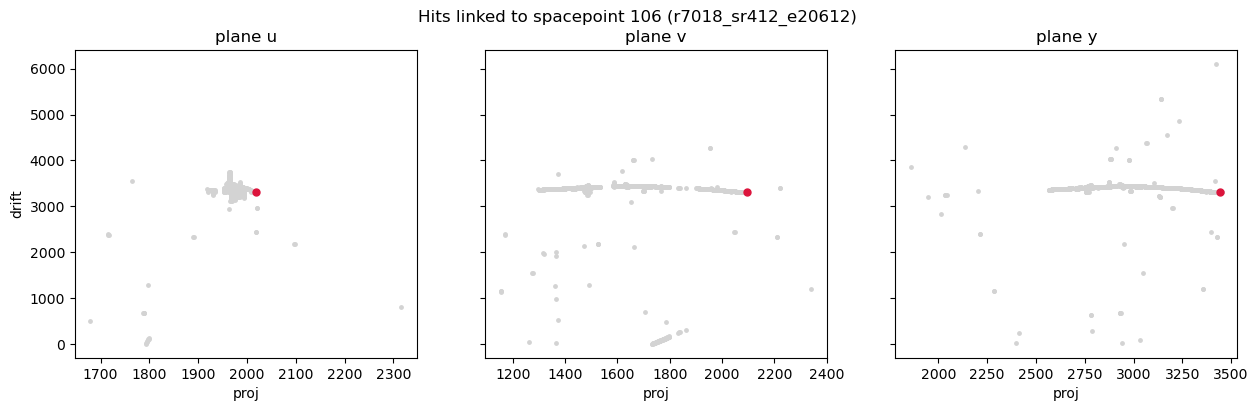

In [45]:
hit = data['hit']
print(hit.keys())   # check which attributes exist

nx = data['hit', 'nexus', 'sp'].edge_index.cpu()   # row 0 = hit index, row 1 = spacepoint index
hits_per_sp = torch.bincount(nx[1], minlength=data['sp'].num_nodes)
print(f"{nx.size(1)} nexus edges, {data['sp'].num_nodes} spacepoints")
print("hits per spacepoint (min/median/max):",
      hits_per_sp.min().item(), hits_per_sp.median().item(), hits_per_sp.max().item())

# highlight the hits that feed one spacepoint, in each wire plane
SP_ID = int(hits_per_sp.argmax())          # change to any spacepoint index
linked = set(nx[0][nx[1] == SP_ID].tolist())
pos, plane = hit.pos.cpu(), hit.plane.cpu()   # assumed attribute names

fig_nx, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for p, ax in enumerate(axes):
    idx = (plane == p).nonzero().flatten()
    is_linked = torch.tensor([i.item() in linked for i in idx], dtype=torch.bool)
    ax.scatter(pos[idx[~is_linked], 0], pos[idx[~is_linked], 1], s=6, color='lightgray')
    ax.scatter(pos[idx[is_linked], 0], pos[idx[is_linked], 1], s=25, color='crimson')
    ax.set_title(f'plane {nudata.planes[p]}')
    ax.set_xlabel('proj')
axes[0].set_ylabel('drift')
fig_nx.suptitle(f'Hits linked to spacepoint {SP_ID} ({name})')
plt.show()

torch.Size([28]) torch.Size([28])


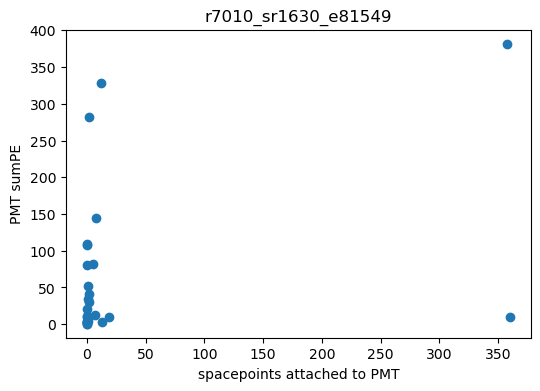

In [47]:
idx = 64                              # any event index
d = nudata.test_dataset[idx]
pe = d['pmt'].x[:, 3].clone()         # sumPE, same column the notebook uses

e = d['sp', 'knn', 'pmt'].edge_index.cpu()
sp_per_pmt = torch.bincount(e[1], minlength=d['pmt'].num_nodes)
print(sp_per_pmt.shape, pe.shape)     # these must match

fig_pe, ax = plt.subplots(figsize=(6, 4))
ax.scatter(sp_per_pmt, pe.cpu())
ax.set_xlabel('spacepoints attached to PMT')
ax.set_ylabel('PMT sumPE')
ax.set_title(f"r{d['metadata'].run}_sr{d['metadata'].subrun}_e{d['metadata'].event}")
plt.show()